# Practical Lab 2 — Learning to Predict Diabetes Progression

## Part 1 — The question and the data
### What am I trying to predict?
The target is a numerical measure of **disease progression one year after baseline**. The 442 people in this dataset already had diabetes. Therefore, this task predicts a progression score, not whether a person has diabetes or their probability of developing it.

The inputs are ten measurements taken at baseline. A model could potentially help physicians prioritize follow-up, but this small lab does not establish a clinically safe screening system. Underestimating progression could miss someone who needs attention; overestimating it could cause unnecessary follow-up.

The workshop concepts help define the evaluation. MAE and MAPE measure numeric prediction error, while classification precision and recall answer different questions about categories. kNN uses nearby patients, so scaling and neighbour count matter. Logistic regression estimates category probabilities, so it requires a separate, clearly defined categorical outcome. These are general conceptual connections; the specific workshop notebooks were not supplied for this report.

### My experiment plan
Use approximately 75% of patients for training, 10% for validation and 15% for testing. Choose regression models by the **lowest validation MAE**; use R² and MAPE to describe other aspects of performance. If MAE ties exactly, keep the simpler model listed first. Test data will be examined only after the model choices are fixed. Five-fold cross-validation on training data provides a separate stability check.

### 1. Load the tools
Pandas stores tables, Matplotlib and Seaborn draw graphs, and scikit-learn supplies the data and models. Run the notebook in order. Installation instructions are in `README.md`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix
import sklearn

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.7.2


### 2. Get the patients' measurements
`as_frame=True` gives pandas tables. `scaled=False` keeps raw feature values, including BMI. The default `scaled=True` would centre and scale the features using the full dataset. I instead fit scaling only inside each model's training pipeline. `return_X_y=True` is an alternative that directly returns separate input and target objects.

| Column | Description |
|---|---|
| age | Age in years |
| sex | Encoded sex |
| bmi | Body mass index |
| bp | Average blood pressure |
| s1, s2, s3 | Total cholesterol, LDL and HDL |
| s4 | Total cholesterol / HDL ratio |
| s5 | Possibly log serum triglycerides; documentation notes uncertainty |
| s6 | Blood sugar |
| progression | Target score measured one year later |

The feature descriptions, especially the serum abbreviations, have documentation limitations. I avoid assuming additional clinical units or causal meaning.

In [2]:
diabetes = load_diabetes(as_frame=True, scaled=False)
X = diabetes.data.copy()
y = diabetes.target.copy()

df = X.copy()
df["progression"] = y

display(df.head())
print("Patients:", len(df))
print("Input features:", X.shape[1])
print("Target range:", y.min(), "to", y.max())

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0


Patients: 442
Input features: 10
Target range: 25.0 to 346.0


### 3. Check quality before modelling
Missing values, infinite values and repeated rows can create problems. Large measurements are not automatically errors, so I do not delete patients simply because their values are unusual.

In [3]:
print("Column types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isna().sum())
print("\nDuplicate complete rows:", df.duplicated().sum())
print("Duplicate feature rows:", X.duplicated().sum())
print("All numbers are finite:", np.isfinite(df.to_numpy()).all())
print("Distinct values per input:")
print(X.nunique())

Column types:
age            float64
sex            float64
bmi            float64
bp             float64
s1             float64
s2             float64
s3             float64
s4             float64
s5             float64
s6             float64
progression    float64
dtype: object

Missing values:
age            0
sex            0
bmi            0
bp             0
s1             0
s2             0
s3             0
s4             0
s5             0
s6             0
progression    0
dtype: int64

Duplicate complete rows: 0
Duplicate feature rows: 0
All numbers are finite: True
Distinct values per input:
age     58
sex      2
bmi    163
bp     100
s1     141
s2     302
s3      63
s4      66
s5     184
s6      56
dtype: int64


**Cleaning decision:** the checks show no missing values, duplicate complete rows, repeated feature vectors or non-finite values. Every input varies. No imputation, deletion or outlier filtering is needed. I retain all 442 patients. Without patient IDs, identical feature vectors would need investigation rather than automatic deletion.

### 4. Set aside validation and test patients
I split before detailed EDA so that only training relationships influence my modelling decisions. Whole patients cannot be divided, so the percentages are approximate. The fixed seed makes the split repeatable.

In [4]:
# Reserve approximately 15% for the final test.
X_remaining, X_test, y_remaining, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42
)

# Set aside 44 validation patients from the remaining observations.
X_train, X_val, y_train, y_val = train_test_split(
    X_remaining, y_remaining, test_size=44, random_state=42
)

split_table = pd.DataFrame({
    "Group": ["Training", "Validation", "Test"],
    "Patients": [len(X_train), len(X_val), len(X_test)]
})
split_table["Percent"] = split_table["Patients"] / len(df) * 100
display(split_table.round(2))

# Confirm no patient appears in more than one group.
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

training_data = X_train.copy()
training_data["progression"] = y_train

,Group,Patients,Percent
0,Training,331,74.89
1,Validation,44,9.95
2,Test,67,15.16


### 5. Describe the training patients
The summary includes the mean, standard deviation, minimum, maximum and quartiles. Different input scales will matter for distance-based kNN.

In [5]:
display(training_data.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
age,331.0,48.17,12.67,19.0,38.50,50.00,58.0,73.00
sex,331.0,1.45,0.50,1.0,1.00,1.00,2.0,2.00
bmi,331.0,26.39,4.33,18.1,23.30,25.80,29.2,41.30
bp,331.0,94.76,13.91,62.0,84.00,93.00,105.0,133.00
s1,331.0,188.29,34.68,110.0,163.00,186.00,208.0,301.00
s2,331.0,114.68,30.49,41.6,94.60,112.40,132.9,242.40
s3,331.0,49.66,13.28,22.0,40.00,48.00,58.0,99.00
s4,331.0,4.08,1.33,2.0,3.00,4.00,5.0,9.09
s5,331.0,4.64,0.52,3.5,4.26,4.62,5.0,6.11
s6,331.0,91.18,11.72,58.0,83.00,91.00,98.0,124.00


### 6. Look at the distributions
Histograms show where most patients fall and whether values are spread unevenly. The encoded sex variable has two distinct values, so its two bars represent categories rather than a continuous measurement.

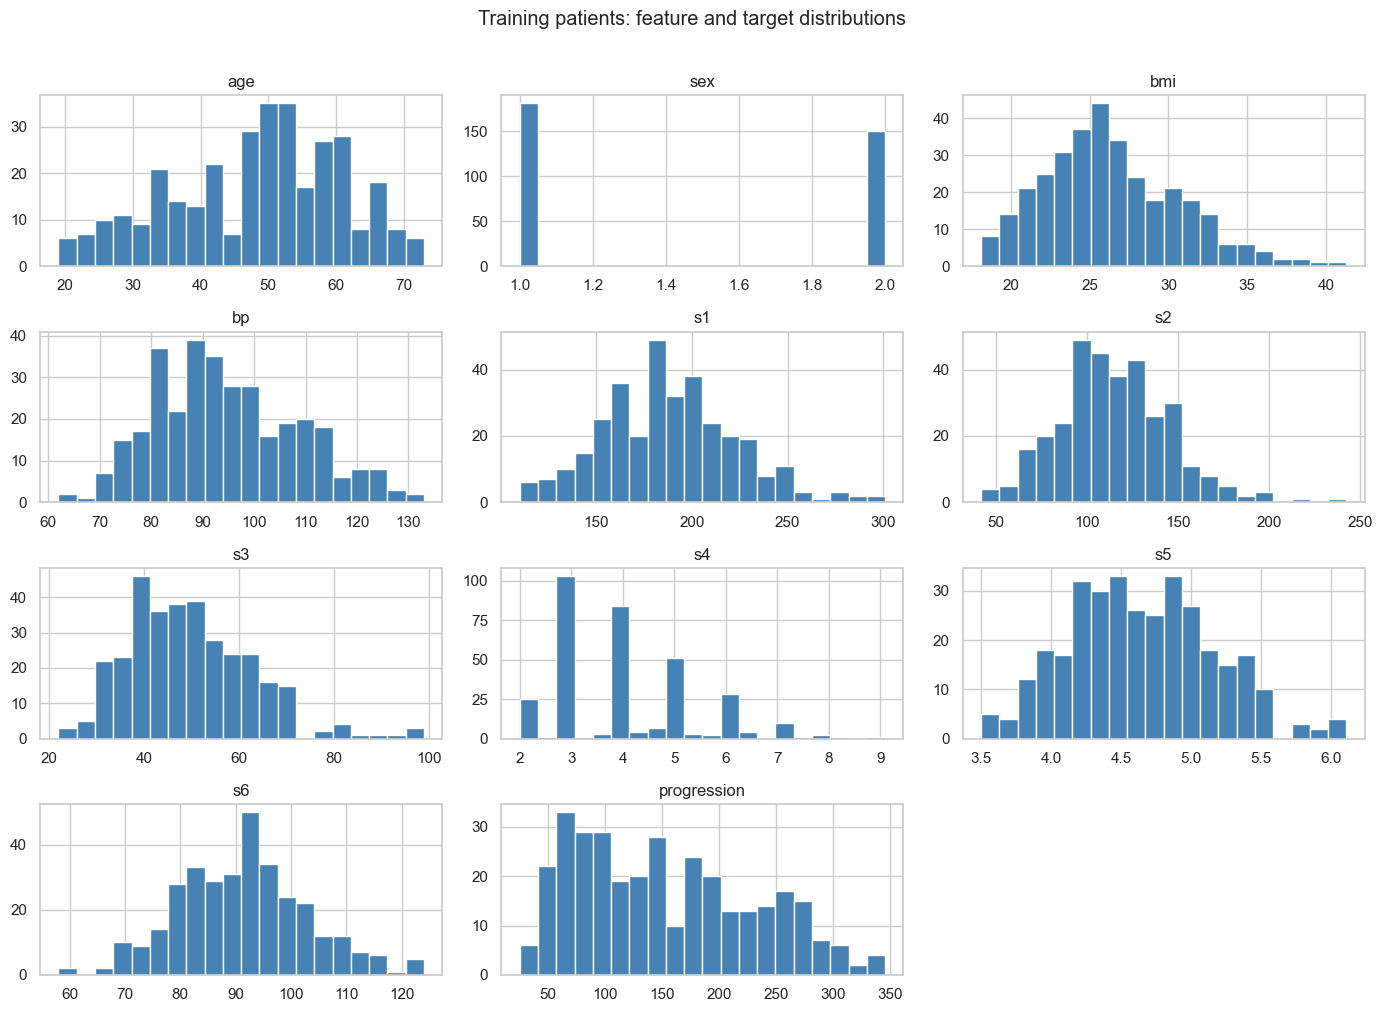

In [6]:
training_data.hist(bins=20, figsize=(14, 10), color="steelblue", edgecolor="white")
plt.suptitle("Training patients: feature and target distributions", y=1.01)
plt.tight_layout()
plt.show()

### 7. Compare each input with progression
Each point is a training patient. A general upward pattern suggests a positive association, but vertical spread shows why one input cannot determine the outcome.

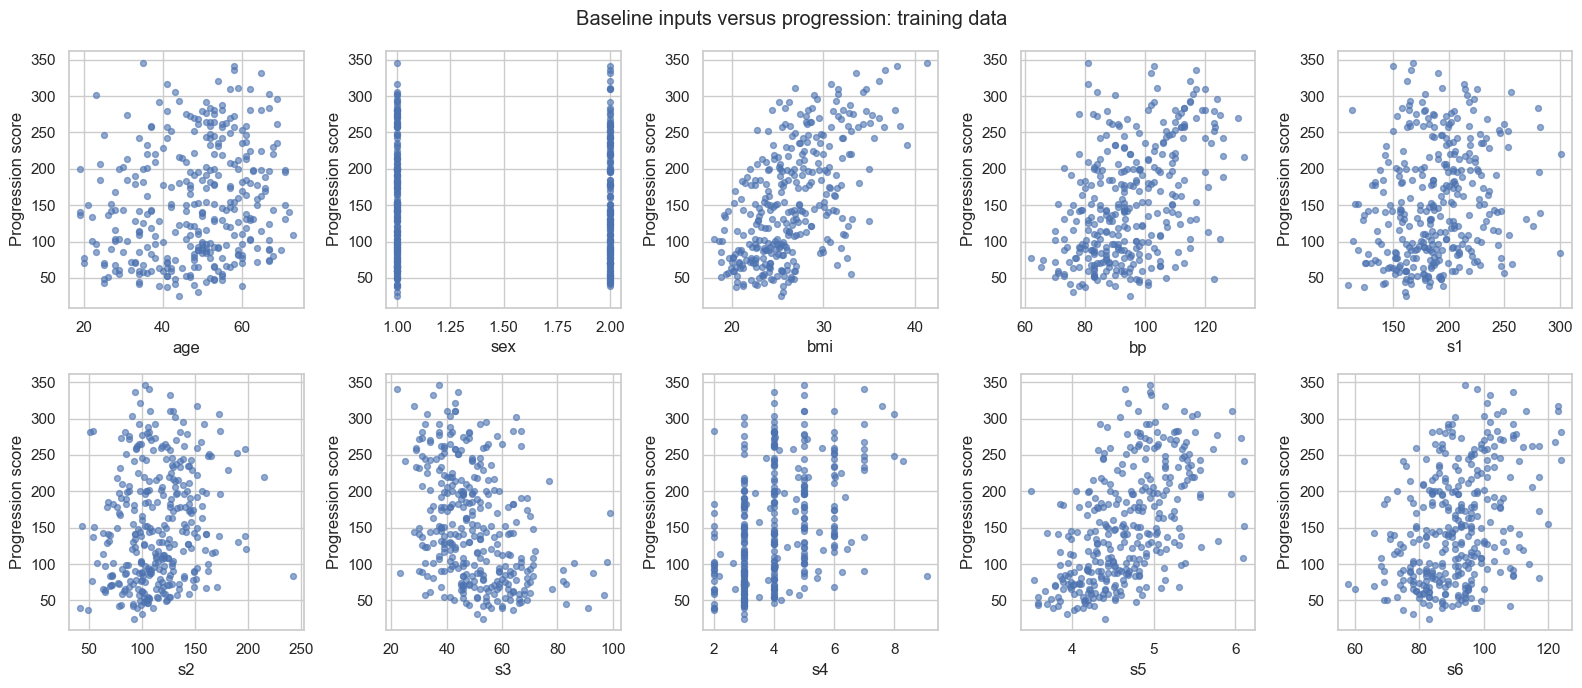

In [30]:
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for column, axis in zip(X.columns, axes.flatten()):
    axis.scatter(X_train[column], y_train, alpha=0.6, s=18)
    axis.set_xlabel(column)
    axis.set_ylabel("Progression score")

fig.suptitle("Baseline inputs versus progression: training data")
plt.tight_layout()
plt.show()

### 8. Check linear associations
Pearson correlation ranges from -1 to +1. Values near zero do not rule out nonlinear relationships. Correlation also does not prove that changing a measurement would change progression.

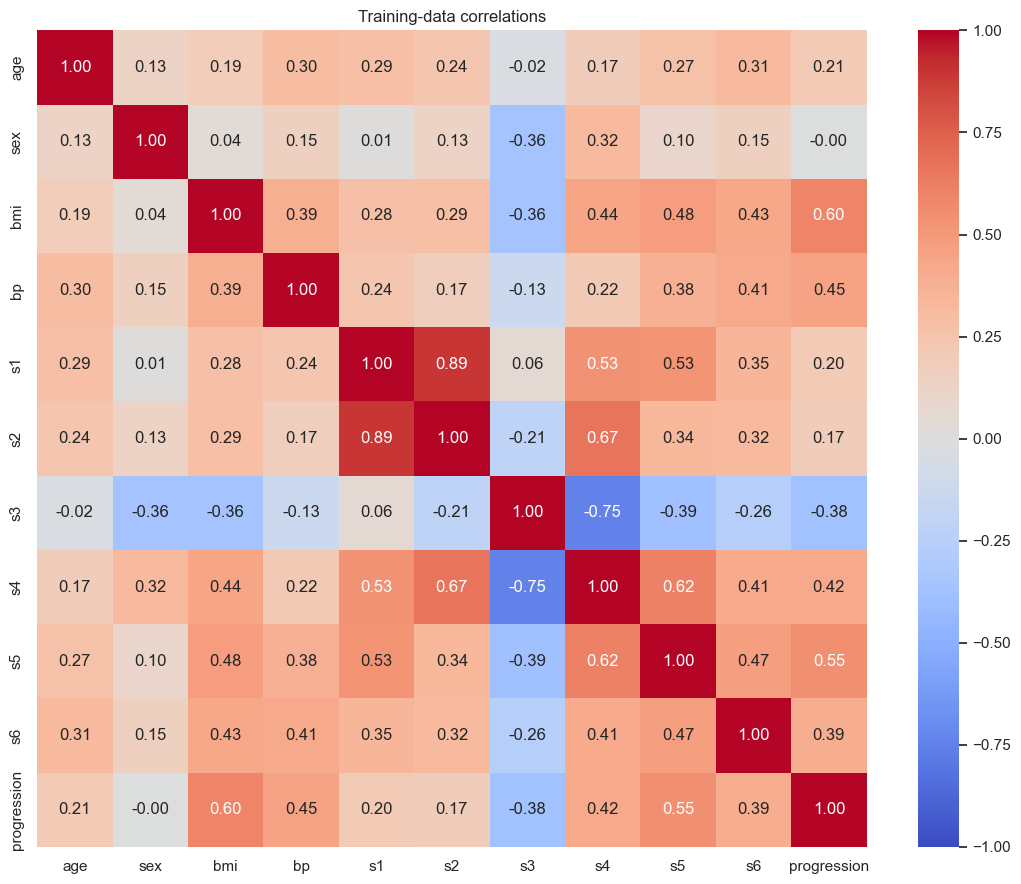

bmi    0.598
s5     0.549
bp     0.449
s4     0.416
s6     0.393
age    0.208
s1     0.202
s2     0.174
sex   -0.004
s3    -0.380
Name: progression, dtype: float64

In [8]:
correlations = training_data.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1)
plt.title("Training-data correlations")
plt.tight_layout()
plt.show()

target_correlations = correlations["progression"].drop("progression")
display(target_correlations.sort_values(ascending=False).round(3))

### What the exploration tells me
The BMI and serum-marker scatter plots show useful associations but also substantial overlap in progression. The correlation table identifies which linear associations are strongest in this training partition. Several serum measurements are related to one another, so high-degree polynomial terms may be redundant and unstable.

I keep **all ten inputs** in Part 3. A weak individual correlation is not enough evidence that a feature is useless when combined with others. This also avoids adding a feature-selection stage to a small dataset. Scaling will be learned from training observations only. No test data have been used in this exploration.

## Part 2 — How much can BMI alone tell us?
### 9. Define the comparison
I fit polynomial degrees 0, 1, 2, 3, 4 and 5. Degree 0 always predicts the training mean. Degree 1 is a straight line; higher degrees add powers and can bend more.

For stability, the pipeline first standardizes raw BMI: **z = (BMI - training mean) / training standard deviation**. A polynomial in z is still a polynomial in BMI. I include one constant term and disable a second intercept, avoiding duplicate constant parameters.

**R²:** higher is better; 1 is perfect and a negative value is worse than predicting the evaluation-set mean. **MAE:** average absolute error in progression-score units, lower is better. **MAPE:** average relative error, reported as a percentage. Scikit-learn returns a fraction, so I multiply by 100. Small actual scores receive more weight in MAPE; the dataset's target has no zeros.

In [9]:
bmi_train = X_train[["bmi"]]
bmi_val = X_val[["bmi"]]
bmi_test = X_test[["bmi"]]

bmi_models = {}
bmi_results = []

for degree in range(6):
    model = Pipeline([
        ("scale", StandardScaler()),
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=True)),
        ("regression", LinearRegression(fit_intercept=False))
    ])
    model.fit(bmi_train, y_train)
    bmi_models[degree] = model

    train_predictions = model.predict(bmi_train)
    val_predictions = model.predict(bmi_val)

    bmi_results.append({
        "Degree": degree,
        "Train R2": r2_score(y_train, train_predictions),
        "Train MAE": mean_absolute_error(y_train, train_predictions),
        "Train MAPE (%)": mean_absolute_percentage_error(y_train, train_predictions) * 100,
        "Validation R2": r2_score(y_val, val_predictions),
        "Validation MAE": mean_absolute_error(y_val, val_predictions),
        "Validation MAPE (%)": mean_absolute_percentage_error(y_val, val_predictions) * 100
    })

bmi_table = pd.DataFrame(bmi_results)
display(bmi_table.round(3))

,Degree,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,0,0.000,66.700,63.438,-0.001,62.555,59.350
1,1,0.357,52.182,48.350,0.426,42.410,41.165
2,2,0.358,52.171,48.334,0.426,42.192,41.036
3,3,0.358,52.120,48.235,0.423,42.205,40.992
4,4,0.361,51.857,47.858,0.426,42.274,40.920
5,5,0.362,51.733,47.729,0.431,42.384,41.012


### 10. Choose the BMI model using validation data
The best training fit is not necessarily the best predictor. I use validation MAE to choose one degree before looking at test results.

In [10]:
best_bmi_row = bmi_table.sort_values(["Validation MAE", "Degree"]).iloc[0]
best_degree = int(best_bmi_row["Degree"])
best_bmi_model = bmi_models[best_degree]

print("Selected degree:", best_degree)
print("Validation MAE:", round(best_bmi_row["Validation MAE"], 2))

Selected degree: 2
Validation MAE: 42.19


**Comparison:** degree 2 has the lowest validation MAE (about 42.19). Degrees 1 through 5 are very close, so this small advantage is not strong evidence that a quadratic will always be better. The constant baseline is much worse. Increasing degree gradually improves training error without a clear validation benefit.

### 11. Write the equation and count coefficients
For degree d, the equation is `prediction = b0 + b1*z + ... + bd*z**d`, containing **d + 1 regression coefficients**. The scaler's mean and standard deviation are two additional learned preprocessing statistics, not regression coefficients.

The selected model's coefficients below give its complete equation to two decimal places. Predictions use full precision; using rounded numbers manually can introduce rounding error.

In [11]:
bmi_mean = best_bmi_model.named_steps["scale"].mean_[0]
bmi_std = best_bmi_model.named_steps["scale"].scale_[0]
bmi_coefficients = best_bmi_model.named_steps["regression"].coef_

print(f"z = (raw BMI - {bmi_mean:.2f}) / {bmi_std:.2f}")
print("Equation: predicted progression =")
for power, coefficient in enumerate(bmi_coefficients):
    print(f"  + ({coefficient:.2f}) * z**{power}")

parameter_rows = []
for degree in range(6):
    terms = bmi_models[degree].named_steps["polynomial"].get_feature_names_out(["z"])
    parameter_rows.append({"Degree": degree, "Terms": ", ".join(terms),
                           "Regression coefficients": len(terms)})
display(pd.DataFrame(parameter_rows))

z = (raw BMI - 26.39) / 4.32
Equation: predicted progression =
  + (151.95) * z**0
  + (45.83) * z**1
  + (1.41) * z**2


,Degree,Terms,Regression coefficients
0,0,1,1
1,1,"1, z",2
2,2,"1, z, z^2",3
3,3,"1, z, z^2, z^3",4
4,4,"1, z, z^2, z^3, z^4",5
5,5,"1, z, z^2, z^3, z^4, z^5",6


### 12. Try one BMI value
I use raw BMI **28.0**, which lies inside the training BMI range. The pipeline automatically applies its training-fitted standardization before predicting. The output is a progression score, not a probability.

In [12]:
example_bmi = pd.DataFrame({"bmi": [28.0]})
example_prediction = best_bmi_model.predict(example_bmi)

print("Training BMI range:", bmi_train.bmi.min(), "to", bmi_train.bmi.max())
print("Expected progression score for BMI 28:", round(example_prediction[0], 2))

Training BMI range: 18.1 to 41.3
Expected progression score for BMI 28: 169.24


## Part 3 — Compare models that use all measurements
### 13. Fit the six regressors
Two polynomial models use degrees 2 and 3. Two trees use maximum depths 3 and 6. Two kNN models use 5 and 15 neighbours. These choices are fixed before test evaluation.

I keep separate model definitions so each setting is visible. Scaling matters for kNN because distance is affected by input units. Trees do not need scaling because their splits compare one feature at a time.

In [13]:
polynomial_2 = Pipeline([
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=True)),
    ("regression", LinearRegression(fit_intercept=False))
])
polynomial_2.fit(X_train, y_train)

,steps,"[('scale', ...), ('polynomial', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,2
,interaction_only,False
,include_bias,True
,order,'C'


In [14]:
polynomial_3 = Pipeline([
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=3, include_bias=True)),
    ("regression", LinearRegression(fit_intercept=False))
])
polynomial_3.fit(X_train, y_train)

,steps,"[('scale', ...), ('polynomial', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,degree,3
,interaction_only,False
,include_bias,True
,order,'C'


In [15]:
tree_3 = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_3.fit(X_train, y_train)

tree_6 = DecisionTreeRegressor(max_depth=6, random_state=42)
tree_6.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [16]:
knn_5 = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=5))
])
knn_5.fit(X_train, y_train)

,steps,"[('scale', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


In [17]:
knn_15 = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsRegressor(n_neighbors=15))
])
knn_15.fit(X_train, y_train)

,steps,"[('scale', ...), ('knn', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,n_neighbors,15
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30


### 14. Put training and validation results in one table
The loop repeats the same six metric calculations for each fitted model. This keeps the comparison consistent without using custom functions.

In [18]:
regression_models = {
    "Polynomial degree 2": polynomial_2,
    "Polynomial degree 3": polynomial_3,
    "Tree depth 3": tree_3,
    "Tree depth 6": tree_6,
    "kNN 5 neighbours": knn_5,
    "kNN 15 neighbours": knn_15
}
regression_rows = []

for name, model in regression_models.items():
    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)
    regression_rows.append({
        "Model": name,
        "Train R2": r2_score(y_train, train_predictions),
        "Train MAE": mean_absolute_error(y_train, train_predictions),
        "Train MAPE (%)": mean_absolute_percentage_error(y_train, train_predictions) * 100,
        "Validation R2": r2_score(y_val, val_predictions),
        "Validation MAE": mean_absolute_error(y_val, val_predictions),
        "Validation MAPE (%)": mean_absolute_percentage_error(y_val, val_predictions) * 100
    })

regression_table = pd.DataFrame(regression_rows)
display(regression_table.round(3))

# Fix the best model in each family before using the test set.
selected_polynomial_name = regression_table.iloc[0:2].sort_values("Validation MAE").iloc[0]["Model"]
selected_tree_name = regression_table.iloc[2:4].sort_values("Validation MAE").iloc[0]["Model"]
selected_knn_name = regression_table.iloc[4:6].sort_values("Validation MAE").iloc[0]["Model"]
best_regression_name = regression_table.sort_values("Validation MAE").iloc[0]["Model"]
print("Selected polynomial:", selected_polynomial_name)
print("Selected tree:", selected_tree_name)
print("Selected kNN:", selected_knn_name)
print("Overall selected regressor:", best_regression_name)

,Model,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,Polynomial degree 2,0.600,39.642,34.869,0.585,38.104,41.867
1,Polynomial degree 3,0.910,16.311,15.100,-132.270,296.998,199.337
2,Tree depth 3,0.535,43.548,37.666,0.392,42.118,44.286
3,Tree depth 6,0.788,25.925,22.874,0.126,52.018,50.777
4,kNN 5 neighbours,0.582,39.805,34.324,0.421,44.645,46.053
5,kNN 15 neighbours,0.492,44.456,39.175,0.546,39.891,41.378


Selected polynomial: Polynomial degree 2
Selected tree: Tree depth 3
Selected kNN: kNN 15 neighbours
Overall selected regressor: Polynomial degree 2


**What changed with model complexity?** The degree-2 polynomial has the lowest validation MAE among these six models. The cubic reduces training MAE to about 16.31 but its validation MAE rises to about 297.00: a clear failure to generalize. The deeper tree also improves training fit but worsens validation MAE. kNN with 15 neighbours performs better on validation than kNN with 5, suggesting that more averaging helps on this split.

### 15. Handle the two logistic models honestly
Logistic regression cannot directly fit a continuous outcome as a regression target. For the assignment's two logistic models, I create an **exploratory category**: progression above the training median is 1, otherwise 0. I use that same training-derived cutoff for validation and test. It is not a clinical threshold.

The models use `C=0.1` and `C=1.0`; smaller C means stronger L2 regularization. I choose the classifier with higher validation recall, breaking ties by higher ROC AUC and then smaller C. Recall is relevant because a false negative misses a patient in this relative high-progression group. Precision describes how often a predicted high label is correct. Neither category represents a validated medical risk group.

MAE, MAPE and R² do not evaluate progression-score prediction when applied to these binary labels. In particular, zero labels make ordinary MAPE unsuitable. I report the requested continuous-target metrics as **not applicable** for these classifiers, and use proper classification metrics instead. This is a documented interpretation of an inconsistent requirement; instructor clarification may be needed.

In [19]:
progression_cutoff = y_train.median()
train_categories = (y_train > progression_cutoff).astype(int)
val_categories = (y_val > progression_cutoff).astype(int)

print("Training-median cutoff:", progression_cutoff)
print("Training category counts:")
print(train_categories.value_counts())

logistic_01 = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(C=0.1, max_iter=3000, random_state=42))
])
logistic_01.fit(X_train, train_categories)

logistic_1 = Pipeline([
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(C=1.0, max_iter=3000, random_state=42))
])
logistic_1.fit(X_train, train_categories)

Training-median cutoff: 142.0
Training category counts:
target
0    168
1    163
Name: count, dtype: int64


,steps,"[('scale', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [20]:
logistic_models = {"Logistic C=0.1": logistic_01, "Logistic C=1.0": logistic_1}
classification_rows = []

for name, model in logistic_models.items():
    for group, inputs, actual in [
        ("Training", X_train, train_categories),
        ("Validation", X_val, val_categories)
    ]:
        predicted_categories = model.predict(inputs)
        probabilities = model.predict_proba(inputs)[:, 1]
        classification_rows.append({
            "Model": name, "Group": group,
            "Accuracy": accuracy_score(actual, predicted_categories),
            "Precision": precision_score(actual, predicted_categories, zero_division=0),
            "Recall": recall_score(actual, predicted_categories, zero_division=0),
            "F1": f1_score(actual, predicted_categories, zero_division=0),
            "ROC AUC": roc_auc_score(actual, probabilities)
        })

classification_table = pd.DataFrame(classification_rows)
display(classification_table.round(3))

validation_classifiers = classification_table[classification_table["Group"] == "Validation"]
best_logistic_name = validation_classifiers.sort_values(
    ["Recall", "ROC AUC"], ascending=False, kind="stable"
).iloc[0]["Model"]
best_logistic_model = logistic_models[best_logistic_name]
print("Selected classifier:", best_logistic_name)

# Show all eight required Part 3 models with the metric distinction visible.
logistic_na_rows = pd.DataFrame({
    "Model": list(logistic_models),
    "Train R2": [np.nan, np.nan], "Train MAE": [np.nan, np.nan],
    "Train MAPE (%)": [np.nan, np.nan], "Validation R2": [np.nan, np.nan],
    "Validation MAE": [np.nan, np.nan], "Validation MAPE (%)": [np.nan, np.nan]
})
all_eight_models = pd.concat([regression_table, logistic_na_rows], ignore_index=True)
display(all_eight_models.round(3).fillna("N/A: classification"))

,Model,Group,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic C=0.1,Training,0.731,0.731,0.718,0.724,0.840
1,Logistic C=0.1,Validation,0.841,0.818,0.857,0.837,0.919
2,Logistic C=1.0,Training,0.731,0.726,0.730,0.728,0.842
3,Logistic C=1.0,Validation,0.818,0.783,0.857,0.818,0.917


Selected classifier: Logistic C=0.1


,Model,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,Polynomial degree 2,0.6,39.642,34.869,0.585,38.104,41.867
1,Polynomial degree 3,0.91,16.311,15.1,-132.27,296.998,199.337
2,Tree depth 3,0.535,43.548,37.666,0.392,42.118,44.286
3,Tree depth 6,0.788,25.925,22.874,0.126,52.018,50.777
4,kNN 5 neighbours,0.582,39.805,34.324,0.421,44.645,46.053
5,kNN 15 neighbours,0.492,44.456,39.175,0.546,39.891,41.378
6,Logistic C=0.1,N/A: classification,N/A: classification,N/A: classification,N/A: classification,N/A: classification,N/A: classification
7,Logistic C=1.0,N/A: classification,N/A: classification,N/A: classification,N/A: classification,N/A: classification,N/A: classification


### 16. Explain equations and model size
For multivariate polynomials, `z_age`, `z_bmi`, etc. mean inputs standardized using the training mean and standard deviation. The fitted equation is the sum of each listed coefficient multiplied by its named term. The coefficient tables below describe both polynomial equations to two decimals; calculations retain full precision.

With 10 inputs, degree 2 produces 66 terms including its constant, and degree 3 produces 286. These are **nominal fitted coefficient counts**, not necessarily independent parameters. Powers of the binary sex variable create dependent columns, and other correlations can increase instability. The cubic approaches the 331-row training size and exceeds the number of rows used in each CV training fold.

Trees predict a training-target mean in the leaf reached by feature thresholds. kNN predicts the average target of the k nearest standardized training patients. These models have no single global polynomial equation. k is a hyperparameter selected in advance, not a fitted coefficient.

In [21]:
for name, model in [("Degree 2", polynomial_2), ("Degree 3", polynomial_3)]:
    terms = model.named_steps["polynomial"].get_feature_names_out(X.columns)
    coefficients = model.named_steps["regression"].coef_
    print(name, "equation: prediction = sum(coefficient * named standardized term)")
    # Print every term so the complete equation can be reconstructed.
    coefficient_table = pd.DataFrame({"Term": terms, "Coefficient": coefficients})
    print(coefficient_table.round(2).to_string(index=False))
    print("Nominal regression coefficients:", len(terms))
    print("Additional scaler statistics:", 2 * X.shape[1])

for name, model in [("Tree depth 3", tree_3), ("Tree depth 6", tree_6)]:
    print(name, "internal splits:", model.tree_.node_count - model.get_n_leaves(),
          "leaf means:", model.get_n_leaves())

print("Both kNN models store", len(X_train), "training rows and their target values.")

Degree 2 equation: prediction = sum(coefficient * named standardized term)
   Term  Coefficient
      1       -24.35
    age         7.17
    sex        -9.07
    bmi        19.05
     bp        20.23
     s1     -2144.77
     s2      1879.58
     s3       807.62
     s4         1.92
     s5       731.24
     s6         0.47
  age^2         5.21
age sex         2.77
age bmi        -2.30
 age bp         5.26
 age s1         5.44
 age s2       -21.79
 age s3         8.72
 age s4        18.36
 age s5        -0.41
 age s6        -0.10
  sex^2       -26.05
sex bmi        -0.46
 sex bp         3.45
 sex s1        -9.44
 sex s2        15.34
 sex s3        -0.98
 sex s4       -14.61
 sex s5         8.25
 sex s6         2.90
  bmi^2         1.58
 bmi bp         9.44
 bmi s1       -17.21
 bmi s2        18.77
 bmi s3        -0.40
 bmi s4        -5.70
 bmi s5         5.62
 bmi s6         0.63
   bp^2        -0.74
  bp s1        60.74
  bp s2       -44.51
  bp s3       -26.19
  bp s4        -5.49
 

In [22]:
for name, model in logistic_models.items():
    coefficients = model.named_steps["classifier"].coef_[0]
    intercept = model.named_steps["classifier"].intercept_[0]
    print("\n", name)
    print(f"Log-odds = {intercept:.2f}")
    for feature, coefficient in zip(X.columns, coefficients):
        print(f"  + ({coefficient:.2f}) * z_{feature}")
    print("p = 1 / (1 + exp(-log_odds)); predict class 1 when p >= 0.5")
    print("Fitted logistic parameters: 10 weights + 1 intercept = 11")
    print("Additional scaler statistics: 20")


 Logistic C=0.1
Log-odds = -0.00
  + (0.18) * z_age
  + (-0.44) * z_sex
  + (0.55) * z_bmi
  + (0.47) * z_bp
  + (-0.15) * z_s1
  + (-0.15) * z_s2
  + (-0.32) * z_s3
  + (0.17) * z_s4
  + (0.52) * z_s5
  + (0.11) * z_s6
p = 1 / (1 + exp(-log_odds)); predict class 1 when p >= 0.5
Fitted logistic parameters: 10 weights + 1 intercept = 11
Additional scaler statistics: 20

 Logistic C=1.0
Log-odds = 0.00
  + (0.23) * z_age
  + (-0.59) * z_sex
  + (0.65) * z_bmi
  + (0.57) * z_bp
  + (-0.47) * z_s1
  + (0.03) * z_s2
  + (-0.32) * z_s3
  + (0.16) * z_s4
  + (0.75) * z_s5
  + (0.06) * z_s6
p = 1 / (1 + exp(-log_odds)); predict class 1 when p >= 0.5
Fitted logistic parameters: 10 weights + 1 intercept = 11
Additional scaler statistics: 20


### 17. Make predictions for an illustrative patient
The profile uses the training medians and raw BMI 28. It is a constructed demonstration, not a real patient; a median profile need not be clinically typical. The six regressors predict progression scores. Logistic models output the probability and category of the separate above-median label.

In [23]:
example_patient = X_train.median().to_frame().T
example_patient["bmi"] = 28.0
display(example_patient)

for name, model in regression_models.items():
    print(name, "progression prediction:", round(model.predict(example_patient)[0], 2))

for name, model in logistic_models.items():
    print(name, "probability of above-median class:",
          round(model.predict_proba(example_patient)[0, 1], 3),
          "predicted class:", model.predict(example_patient)[0])

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,50.0,1.0,28.0,93.0,186.0,112.4,48.0,4.0,4.625,91.0


Polynomial degree 2 progression prediction: -161.86
Polynomial degree 3 progression prediction: 20839.95
Tree depth 3 progression prediction: 171.75
Tree depth 6 progression prediction: 140.66
kNN 5 neighbours progression prediction: 182.6
kNN 15 neighbours progression prediction: 156.67
Logistic C=0.1 probability of above-median class: 0.646 predicted class: 1
Logistic C=1.0 probability of above-median class: 0.685 predicted class: 1


### 18. Check stability with five-fold cross-validation
I run five-fold CV using only the original training partition. Each fold fits a fresh model and its own scaler; the outer validation and test sets are not used. The six multivariate regressors and six BMI degrees are checked. The mean describes typical held-out-fold error and the standard deviation shows its variability.

CV is a diagnostic here. My predeclared choice remains validation MAE, even if CV suggests a different ranking. A stronger future experiment could use CV as the selection rule from the outset and reserve an independent final test set.

In [24]:
folds = KFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []

for name, model in regression_models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=folds,
        scoring={"MAE": "neg_mean_absolute_error", "R2": "r2",
                 "MAPE": "neg_mean_absolute_percentage_error"}
    )
    cv_rows.append({
        "Model": name,
        "CV MAE mean": -scores["test_MAE"].mean(),
        "CV MAE SD": scores["test_MAE"].std(),
        "CV R2 mean": scores["test_R2"].mean(),
        "CV MAPE (%)": -scores["test_MAPE"].mean() * 100
    })

cv_table = pd.DataFrame(cv_rows)
display(cv_table.round(3))

bmi_cv_rows = []
for degree, model in bmi_models.items():
    scores = cross_validate(model, bmi_train, y_train, cv=folds,
        scoring={"MAE": "neg_mean_absolute_error", "R2": "r2",
                 "MAPE": "neg_mean_absolute_percentage_error"})
    bmi_cv_rows.append({
        "Degree": degree,
        "CV MAE mean": -scores["test_MAE"].mean(),
        "CV MAE SD": scores["test_MAE"].std(),
        "CV R2 mean": scores["test_R2"].mean(),
        "CV MAPE (%)": -scores["test_MAPE"].mean() * 100
    })
display(pd.DataFrame(bmi_cv_rows).round(3))

,Model,CV MAE mean,CV MAE SD,CV R2 mean,CV MAPE (%)
0,Polynomial degree 2,51.439,3.722,0.245,43.393
1,Polynomial degree 3,2099.704,1091.197,-3409.024,1712.167
2,Tree depth 3,51.338,3.432,0.330,43.649
3,Tree depth 6,55.088,5.442,0.182,46.009
4,kNN 5 neighbours,49.125,3.051,0.353,41.999
5,kNN 15 neighbours,48.416,2.626,0.414,42.325


,Degree,CV MAE mean,CV MAE SD,CV R2 mean,CV MAPE (%)
0,0,66.739,3.158,-0.011,63.479
1,1,52.555,3.071,0.333,48.586
2,2,52.720,2.987,0.328,48.704
3,3,52.733,2.994,0.325,48.645
4,4,52.767,3.071,0.327,48.456
5,5,53.220,3.648,0.313,48.631


**CV interpretation:** kNN with 15 neighbours has lower mean CV MAE (48.42) than the multivariate quadratic (51.44), despite the opposite validation ranking. The cubic's CV MAE is extremely large, confirming instability rather than a reliable improvement. For BMI, the linear model's CV MAE is slightly lower than the quadratic's. These differences show why model selection from only 44 validation patients is uncertain.

## Final evaluation — use the reserved patients once choices are fixed
### 19. Test the selected models
The BMI degree, the winner in each regression family, the overall regressor and the logistic classifier have already been selected. I now evaluate them without refitting or changing hyperparameters. Keeping the original fits means the equations and later graphs describe exactly the tested models. I do not switch the final winner using test performance.

In [25]:
chosen_regressors = {
    selected_polynomial_name: regression_models[selected_polynomial_name],
    selected_tree_name: regression_models[selected_tree_name],
    selected_knn_name: regression_models[selected_knn_name]
}
test_rows = []

bmi_test_predictions = best_bmi_model.predict(bmi_test)
test_rows.append({
    "Model": f"BMI degree {best_degree}",
    "Test R2": r2_score(y_test, bmi_test_predictions),
    "Test MAE": mean_absolute_error(y_test, bmi_test_predictions),
    "Test MAPE (%)": mean_absolute_percentage_error(y_test, bmi_test_predictions) * 100
})

for name, model in chosen_regressors.items():
    predictions = model.predict(X_test)
    test_rows.append({
        "Model": name,
        "Test R2": r2_score(y_test, predictions),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test MAPE (%)": mean_absolute_percentage_error(y_test, predictions) * 100
    })

test_table = pd.DataFrame(test_rows)
display(test_table.round(3))

,Model,Test R2,Test MAE,Test MAPE (%)
0,BMI degree 2,0.199,54.989,48.751
1,Polynomial degree 2,0.334,45.986,39.578
2,Tree depth 3,0.308,50.371,44.903
3,kNN 15 neighbours,0.411,46.107,42.070


In [26]:
test_categories = (y_test > progression_cutoff).astype(int)
test_class_predictions = best_logistic_model.predict(X_test)
test_probabilities = best_logistic_model.predict_proba(X_test)[:, 1]

classification_test = pd.DataFrame([{
    "Model": best_logistic_name,
    "Accuracy": accuracy_score(test_categories, test_class_predictions),
    "Precision": precision_score(test_categories, test_class_predictions, zero_division=0),
    "Recall": recall_score(test_categories, test_class_predictions, zero_division=0),
    "F1": f1_score(test_categories, test_class_predictions, zero_division=0),
    "ROC AUC": roc_auc_score(test_categories, test_probabilities)
}])
display(classification_test.round(3))

confusion = confusion_matrix(test_categories, test_class_predictions, labels=[0, 1])
display(pd.DataFrame(confusion, index=["Actual lower", "Actual higher"],
                     columns=["Predicted lower", "Predicted higher"]))

,Model,Accuracy,Precision,Recall,F1,ROC AUC
0,Logistic C=0.1,0.746,0.71,0.733,0.721,0.823


,Predicted lower,Predicted higher
Actual lower,28,9
Actual higher,8,22


### 20. Draw the selected BMI curve over each group
The curve is fitted only on training patients. A sorted BMI grid keeps the line smooth. The training, validation and test points are shown separately so differences in fit are visible. Multivariate fit plots are not required.

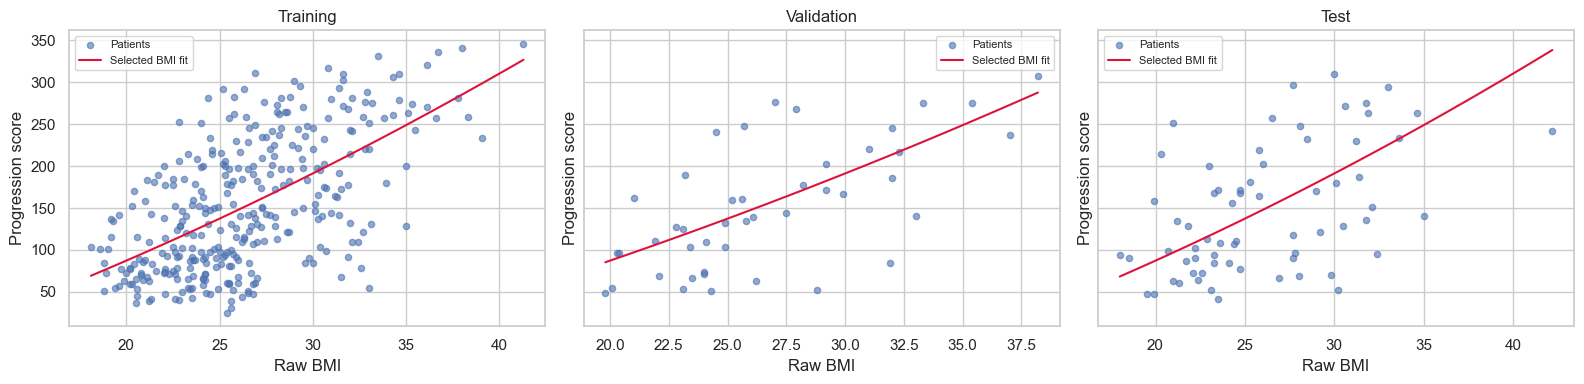

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for axis, title, inputs, actual in [
    (axes[0], "Training", bmi_train, y_train),
    (axes[1], "Validation", bmi_val, y_val),
    (axes[2], "Test", bmi_test, y_test)
]:
    bmi_grid = pd.DataFrame({"bmi": np.linspace(inputs.bmi.min(), inputs.bmi.max(), 200)})
    fitted_curve = best_bmi_model.predict(bmi_grid)
    axis.scatter(inputs.bmi, actual, alpha=0.6, s=20, label="Patients")
    axis.plot(bmi_grid.bmi, fitted_curve, color="crimson", label="Selected BMI fit")
    axis.set_title(title)
    axis.set_xlabel("Raw BMI")
    axis.set_ylabel("Progression score")
    axis.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 21. Find the mistakes hidden by average scores
A residual is `actual - predicted`. Positive residuals are underestimates, negative ones are overestimates. I inspect both the selected BMI model and selected overall regressor. Low/middle/high groups use progression cutoffs learned from training data, and are used only to describe final errors, not to tune models.

Largest BMI-model errors:


,Actual,Predicted,Residual,Absolute error
78,252.0,96.96,155.04,155.04
56,52.0,193.48,-141.48,141.48
113,297.0,165.99,131.01,131.01
218,214.0,90.13,123.87,123.87
104,95.0,218.45,-123.45,123.45
211,70.0,189.02,-119.02,119.02
9,310.0,191.25,118.75,118.75
407,140.0,248.91,-108.91,108.91


Largest overall-regressor errors:


,Actual,Predicted,Residual,Absolute error
321,230.0,420.42,-190.42,190.42
56,52.0,203.75,-151.75,151.75
9,310.0,183.83,126.17,126.17
211,70.0,188.13,-118.13,118.13
199,90.0,201.47,-111.47,111.47
287,219.0,109.87,109.13,109.13
209,77.0,185.22,-108.22,108.22
77,200.0,96.44,103.56,103.56


BMI model


,Patients,MAE,Mean_residual
Actual group,,,
Low,25,55.36,-51.54
Middle,24,38.40,-6.37
High,18,76.60,65.87


Overall model


,Patients,MAE,Mean_residual
Actual group,,,
Low,25,44.31,-41.11
Middle,24,32.81,4.06
High,18,65.87,33.65


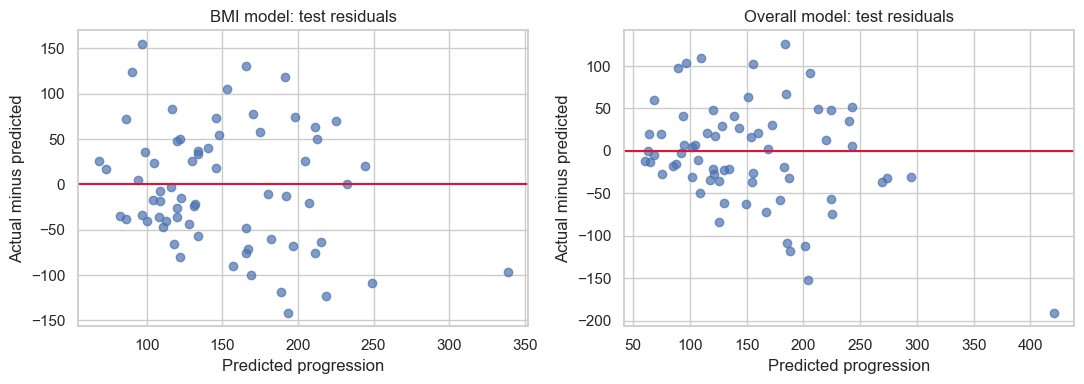

In [28]:
bmi_errors = pd.DataFrame({"Actual": y_test, "Predicted": bmi_test_predictions})
bmi_errors["Residual"] = bmi_errors["Actual"] - bmi_errors["Predicted"]
bmi_errors["Absolute error"] = bmi_errors["Residual"].abs()
print("Largest BMI-model errors:")
display(bmi_errors.sort_values("Absolute error", ascending=False).head(8).round(2))

best_regression_model = regression_models[best_regression_name]
final_predictions = best_regression_model.predict(X_test)
final_errors = pd.DataFrame({"Actual": y_test, "Predicted": final_predictions})
final_errors["Residual"] = final_errors["Actual"] - final_errors["Predicted"]
final_errors["Absolute error"] = final_errors["Residual"].abs()
print("Largest overall-regressor errors:")
display(final_errors.sort_values("Absolute error", ascending=False).head(8).round(2))

lower_boundary = y_train.quantile(1/3)
upper_boundary = y_train.quantile(2/3)
for errors, title in [(bmi_errors, "BMI model"), (final_errors, "Overall model")]:
    errors["Actual group"] = pd.cut(errors["Actual"],
        bins=[-np.inf, lower_boundary, upper_boundary, np.inf],
        labels=["Low", "Middle", "High"])
    print(title)
    display(errors.groupby("Actual group", observed=True).agg(
        Patients=("Actual", "size"), MAE=("Absolute error", "mean"),
        Mean_residual=("Residual", "mean")
    ).round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(bmi_errors["Predicted"], bmi_errors["Residual"], alpha=0.7)
axes[0].axhline(0, color="crimson")
axes[0].set_title("BMI model: test residuals")
axes[0].set_xlabel("Predicted progression")
axes[0].set_ylabel("Actual minus predicted")
axes[1].scatter(final_errors["Predicted"], final_errors["Residual"], alpha=0.7)
axes[1].axhline(0, color="crimson")
axes[1].set_title("Overall model: test residuals")
axes[1].set_xlabel("Predicted progression")
axes[1].set_ylabel("Actual minus predicted")
plt.tight_layout()
plt.show()

## Conclusions
### BMI alone
The selected degree-2 BMI model has test R² **0.199**, MAE **54.99** progression units and MAPE **48.75%**. Its validation MAE was 42.19, so it performs less well on the unseen test patients. The nearly tied validation results across degrees and the CV preference for degree 1 mean the quadratic's advantage is uncertain. The constant baseline is clearly weaker.

The BMI scatter plots show large vertical differences among people with similar BMI. The worst selected BMI-model error is about **155.04** units: a patient with actual progression 252 receives a prediction near 96.96. This substantial underestimate illustrates why BMI alone is insufficient. Higher polynomial degree does not solve the missing-information problem.

### Using all inputs
The multivariate quadratic was selected by validation MAE and has test R² **0.334**, MAE **45.99** and MAPE **39.58%**. Compared with the BMI model, it reduces average absolute error by about **9.00** units on this test partition. That improvement is useful in this experiment but does not make individual predictions reliable.

The cubic overfits severely. The deeper tree also has a larger training-validation gap, while kNN with more neighbours benefits from averaging. Training CV favours kNN with 15 neighbours over the quadratic, so the single validation-set ranking should not be treated as decisive. The selected depth-3 tree has test R² 0.308, MAE 50.37 and MAPE 44.90%; the selected 15-neighbour kNN has test R² 0.411, MAE 46.11 and MAPE 42.07%. kNN has higher test R² than the quadratic but slightly higher test MAE. These metrics describe different aspects of error. I retain the original validation-based choice rather than selecting by the final test results.

### Where predictions fail
For the overall quadratic, high-progression patients have mean residual **+33.65** and MAE **65.87** across 18 patients, showing average underestimation. Low-progression patients have mean residual **-41.11**, indicating overestimation. Middle-group MAE is lower (**32.81**). Errors therefore differ across outcome ranges, which the overall MAE conceals. These small groups do not establish stable population-level performance.

The worst overall prediction is **420.42** for an actual score of **230**, an error of **190.42**. This prediction lies above the dataset's observed target maximum of 346. An unconstrained polynomial can produce unreasonable outputs even for held-out dataset patients. Tree predictions change abruptly at thresholds; kNN averages nearby targets and may miss extremes or struggle where few similar patients exist. Polynomial coefficients can be unstable when inputs and powers are correlated.

### Classification connection and limitations
The selected logistic model (`C=0.1`) has test recall **0.733**, precision **0.710**, **8 false negatives** and **9 false positives**. These refer only to the training-median category, not a validated screening threshold. Accuracy alone would hide which kind of mistake occurred. A clinically justified threshold would require an explicit tradeoff between missed patients and unnecessary follow-up, selected using development data rather than this test set.

The study has only 442 patients, a single random split and no external validation. MAE hides the distribution of individual errors; MAPE overweights small actual scores; R² is not the percentage of correctly classified patients or proof of medical safety. Associations are observational, and missing context such as treatment and representativeness limits interpretation. There are no uncertainty intervals or established subgroup fairness results. Before clinical use, the outcome and screening threshold would need clinical validation, representative external testing, calibration assessment for probabilities, and prospective evaluation. Future modelling could test regularization and use nested CV for more dependable selection. None of the current models should be treated as a diagnosis or treatment decision.

## References and assistance
1. Scikit-learn, [Diabetes dataset documentation](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset).
2. Scikit-learn, [`load_diabetes` parameters](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).
3. CSCN8010, [Notebook organization guidance](https://github.com/CSCN8010/CSCN8010/blob/main/class_notebooks/notebook_structure/notebook_structure.ipynb).
4. Scikit-learn API: [PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html), [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html).
5. UbaidUllah777, [reference repository reviewed for general organization](https://github.com/UbaidUllah777/PracticalLab2_DiabetesRegression). Its prose, classes and code were not copied into this notebook. This analysis retains all ten features and uses its own split, model settings, explanations and outputs.

**Assistance disclosure:** ChatGPT assisted with code, organization and explanations. The analysis and reported outputs should be reviewed in accordance with the course's AI-use policy.